# Прогнозирование фактического времени доставки еды: ML-пайплайн

**Задача (регрессия):** предсказать `actual_delivery_time_minutes` — количество минут от размещения заказа до завершения доставки — по времени приготовления, дистанции, пробкам, погоде и характеристикам заказа. Продолжение исследовательского анализа из `Food_Delivery_Orders.ipynb`: все решения по чистке и признакам взяты из EDA и здесь перепроверяются на моделях.

**Подход:**

| Механика | Решение |
|---|---|
| Валидация | хронологическая: train 1–23 окт, val 24–27 окт, test 28–30 окт; CV — point-in-time фолды (обучение только на завершившихся заказах) |
| Утечки | постфактум-колонки удалены; history-признаки считаются строго по прошлому; test вскрывается один раз |
| Признаки | базовые (взаимодействия дистанции с условиями, время суток) + история сущностей (target encoding по прошлым заказам) + загруженность за последний час |
| Модели | Ridge/Lasso (линейные — простая проверка, что признаки работают и без деревьев), RandomForest, LightGBM, XGBoost, CatBoost (нативный для категорий) |
| Тюнинг | Optuna (TPE) на тех же временных фолдах |
| Таргет | на val выбираем из двух вариантов: учить весь таргет или только «дорожную» часть — остаток `факт − время приготовления` (известное приготовление потом просто прибавляется к прогнозу) |
| Буфер обещания | асимметрия цены ошибки: лучше пообещать чуть больше; буфер подбирается на val |
| Интерпретация | permutation importance + SHAP |

**Про residual двумя словами.** Полное время доставки = приготовление блюд + дорога. Приготовление известно уже в момент заказа — угадывать его не нужно. Поэтому один из вариантов (какой лучше — решит val в разделе 9) учит модель предсказывать только «дорожную» часть: остаток = `факт − приготовление`. К прогнозу модели мы потом просто прибавляем известное время приготовления.

Протокол честности: все решения (модель, признаки, вариант таргета, буфер) принимаются **только на train/val**; последняя оценка — одна на test. `RANDOM_STATE = 42` везде, версии библиотек печатаются, ноутбук исполняется сверху вниз без вмешательств. Зависимости зафиксированы в `requirements.txt` (окружение проверено на Python 3.12).

## Команда и вклад

| Участник | Разделы | Вклад |
|---|---|---|
| **Аленин Даниил** | 1, 2, 4 | проверка временной структуры данных; чистка и проверка формул чека; конструирование признаков: базовые взаимодействия, история сущностей (point-in-time target encoding), загруженность|
| **Валикова Елизавета** | 7 |  абляция — проверка вклада признаков-историй |
| **Новиков Даниил** | 3, 5, 6, 8 | периоды train/val/test и point-in-time корректность; выбор метрик; сравнение шести моделей; сравнение способов масштабирования; Optuna-тюнинг |
| **Мокров Данила** | 9–12 | выбор варианта таргета (прямой/residual) и буфера обещания; финальная оценка на тесте и контроль случайного сплита; сегментный анализ ошибок; интерпретация (permutation importance, SHAP) |
| все | 13 | выводы, взаимное ревью кода |

**Структура:**
1. Данные — временной ряд? Проверка
2. Очистка: утечки и формулы чека
3. Периоды train/val/test, point-in-time и метрики
4. Признаки: базовые, загруженность, история
5. Point-in-time фолды и сравнение моделей
6. Сравнение способов масштабирования (★)
7. Помогают ли признаки-истории? Абляция
8. Optuna: тюнинг LightGBM
9. Выбор на val: таргет (прямой/residual) и буфер обещания
10. Финальная оценка на тесте + контроль случайного сплита
11. Ошибки по сегментам
12. Интерпретация: permutation importance и SHAP
13. Выводы

## 1. Данные — временной ряд? Проверка (автор: Валикова Елизавета)

Заявление: «данные 1–30 октября 2025 — временной ряд, случайный сплит покажет оптимистичную оценку». Проверяем три вещи:

1. **Упорядоченный поток событий** — заказы имеют временную метку и идут потоком, а не независимой выборкой «в вакууме»;
2. **Сущности повторяются во времени** — рестораны и курьеры встречаются много раз → имеет смысл история по ним;
3. **Есть ли дрейф** — если объём и распределение таргета меняются по дням, разница случайного и временного сплитов будет большой; если ряд стационарен — оценка почти совпадёт, но протокол всё равно должен быть временным: модель не имеет права «видеть будущее».

In [1]:
import sys
import warnings
from pathlib import Path

import catboost as catboost_lib
import lightgbm as lightgbm_lib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
import sklearn
import xgboost as xgboost_lib
from sklearn.base import BaseEstimator
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (MinMaxScaler, OneHotEncoder, RobustScaler,
                                   StandardScaler)

#                      базовые признаки, история сущностей (point-in-time TE), загруженность
#                      масштабирование, абляция признаков, Optuna-тюнинг
#                      сегментные ошибки, permutation importance и SHAP

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("Python:", sys.version.split()[0])
for package in (pd, np, sklearn, lightgbm_lib, xgboost_lib, catboost_lib, optuna, shap):
    print(f"{package.__name__} {package.__version__}")

C:\Users\den31\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.6
pandas 3.0.6
numpy 2.5.3
sklearn 1.9.1
lightgbm 4.7.0
xgboost 3.4.1
catboost 1.2.10
optuna 5.1.0
shap 0.54.1


Размер: (50000, 37) | период: 2025-10-01 - 2025-10-30

1) заказов в день: 1557-1706 (вариация 2.3%) — поток равномерный
2) дневное среднее таргета: 33.4-38.7 мин, корреляция дня со средним: +0.13 (тренда нет)
   restaurant_id: 250 уникальных, ~197 заказов на значение; известных в тест-неделе: 100%
   driver_id: 200 уникальных, ~246 заказов на значение; известных в тест-неделе: 100%


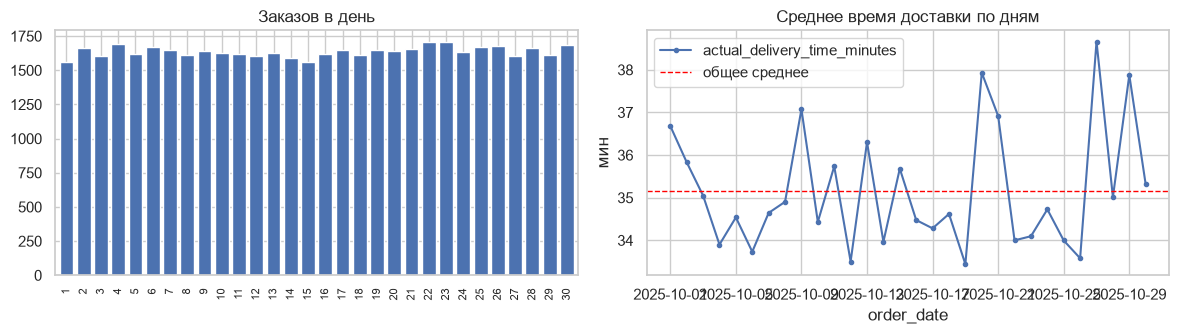

In [2]:
DATASET_FILE = "food_delivery_orders_dataset.csv"

try:  # штатный путь: kagglehub скачает датасет или возьмёт уже скачанный из кэша
    import kagglehub
    dataset_dir = Path(kagglehub.dataset_download(
        "razanihababdellatif/food-delivery-orders-and-eta-logistics-dataset"))
    csv_path = dataset_dir / DATASET_FILE
except Exception as error:  # офлайн-запасной вариант: ищем копию в локальном кэше kagglehub
    print(f"kagglehub недоступен ({type(error).__name__}), ищем датасет в локальном кэше")
    csv_path = next((Path.home() / ".cache" / "kagglehub" / "datasets").rglob(DATASET_FILE))

raw_orders = pd.read_csv(csv_path)
raw_orders["order_timestamp"] = pd.to_datetime(raw_orders["order_timestamp"])
raw_orders["order_date"] = pd.to_datetime(raw_orders["order_date"])
print("Размер:", raw_orders.shape, "| период:",
      raw_orders["order_date"].min().date(), "-", raw_orders["order_date"].max().date())

TARGET = "actual_delivery_time_minutes"
completed_part = raw_orders[raw_orders["order_status"] == "Completed"]

orders_per_day = completed_part.groupby(completed_part["order_date"].dt.date).size()
daily_target_mean = completed_part.groupby(completed_part["order_date"].dt.date)[TARGET].mean()
day_number = np.arange(len(orders_per_day))

print(f"\n1) заказов в день: {orders_per_day.min()}-{orders_per_day.max()} "
      f"(вариация {orders_per_day.std()/orders_per_day.mean()*100:.1f}%) — поток равномерный")
print(f"2) дневное среднее таргета: {daily_target_mean.min():.1f}-{daily_target_mean.max():.1f} мин, "
      f"корреляция дня со средним: {np.corrcoef(day_number, daily_target_mean)[0,1]:+.2f} (тренда нет)")
for column in ("restaurant_id", "driver_id"):
    unique_count = completed_part[column].nunique()
    known_share = completed_part.loc[completed_part["order_date"] >= "2025-10-28", column].isin(
        set(completed_part.loc[completed_part["order_date"] < "2025-10-24", column])).mean()
    print(f"   {column}: {unique_count} уникальных, ~{len(completed_part)/unique_count:.0f} заказов "
          f"на значение; известных в тест-неделе: {known_share*100:.0f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
orders_per_day.plot(kind="bar", ax=ax[0], color="#4C72B0", width=0.8)
ax[0].set_title("Заказов в день"); ax[0].set_xlabel("")
ax[0].set_xticklabels([d.day for d in orders_per_day.index], fontsize=8)
daily_target_mean.plot(ax=ax[1], color="#4C72B0", marker="o", ms=3)
ax[1].axhline(completed_part[TARGET].mean(), color="red", ls="--", lw=1, label="общее среднее")
ax[1].set_title("Среднее время доставки по дням"); ax[1].set_ylabel("мин"); ax[1].legend()
plt.tight_layout(); plt.show()

**Вердикт.** Формально это временной ряд: непрерывный поток заказов с меткой времени, сущности повторяются (250 ресторанов × ~197 заказов, 200 курьеров × ~246), в тест-неделе нет ни одного нового ресторана или курьера — история по ним вычислима. Статистически ряд **почти стационарен**: объём в день варьируется на ±2%, дневное среднее таргета ходит вокруг общего без тренда. Значит: (а) временной сплит обязателен по протоколу; (б) сильного дрейфа не ждём — расхождение со случайным сплитом проверим контролем в разделе 10.

## 2. Очистка: утечки и формулы чека (автор: Валикова Елизавета)

Базовая чистка из EDA — 868 отменённых заказов без таргета, постфактум-колонки:

| Удаляем | Причина |
|---|---|
| заказы со статусом ≠ `Completed` | нет таргета `actual_delivery_time_minutes` |
| `cancellation_reason` | известна только после отмены заказа |
| `late_delivery` | выводится из таргета: `(actual − estimated) > 5` — прямая утечка |
| `customer_rating` | клиент ставит рейтинг после доставки |
| `order_status` | константа `Completed` после фильтрации |
| `tip_amount` | неизвестно, оставляются чаевые до или после заказа; связь с таргетом слабая (corr 0.19) |

Деньги удаляем **по проверенным формулам**, а не только по корреляциям (проверка assert'ами ниже):

| Признак | Проверка | Решение |
|---|---|---|
| `delivery_fee` | для Premium всегда 0; для остальных ровно `2 + 0.5 × distance_km` | удалить — детерминирован `customer_type` + `distance_km`, которые остаются |
| `tax_amount` | ≈ 14% от `subtotal × (1 − discount)` (разброс — округление до копеек) | удалить — детерминирован `subtotal` и `discount_percent` |
| `service_fee` | ~2.4–7.1% от subtotal без точной формулы, corr ≈ 1 с subtotal | удалить — дублирует размер заказа (решение EDA) |
| `order_total` | сходится с формулой чека до копеек | удалить — сумма остальных |

In [3]:
orders = raw_orders[raw_orders["order_status"] == "Completed"].drop(
    columns=["cancellation_reason", "late_delivery", "customer_rating",
             "order_status", "tip_amount"]
).copy()

# проверка формул перед удалением
non_free_delivery = orders[orders["delivery_fee"] > 0]
assert (orders.loc[orders["customer_type"] == "Premium", "delivery_fee"] == 0).all(), "Premium не 0"
assert np.allclose(non_free_delivery["delivery_fee"],
                   2 + 0.5 * non_free_delivery["distance_km"]), "формула delivery_fee не точна"
tax_rate = orders["tax_amount"] / (orders["subtotal"] * (1 - orders["discount_percent"] / 100))
assert tax_rate.between(0.138, 0.142).all(), "tax_amount не ~14%"
print("delivery_fee = 0 для Premium; для остальных ровно 2 + 0.5*distance_km — подтверждено")
print(f"tax_amount / (subtotal*(1-discount)) = {tax_rate.mean():.4f} ± {tax_rate.std():.4f} — подтверждено")

orders = orders.drop(columns=["delivery_fee", "tax_amount", "service_fee", "order_total"])
orders = orders.sort_values("order_timestamp").reset_index(drop=True)  # хронологический порядок
print("Размер после чистки:", orders.shape, "| пропусков:", int(orders.isna().sum().sum()))

delivery_fee = 0 для Premium; для остальных ровно 2 + 0.5*distance_km — подтверждено
tax_amount / (subtotal*(1-discount)) = 0.1400 ± 0.0002 — подтверждено
Размер после чистки: (49132, 28) | пропусков: 0


## 3. Периоды train/val/test, point-in-time корректность и метрики (автор: Новиков Даниил)

- **train**: 1–23 октября — обучение
- **val**: 24–27 октября — все решения: выбор признаков, модели, варианта таргета, буфера
- **test**: 28–30 октября — одна финальная оценка, ничего не настраиваем

**Point-in-time (честность про метки).** В момент прогноза известны только метки заказов, которые уже **завершились**. Поэтому в каждом CV-фолде и в train обучаемся только на заказах, чьё время завершения (`order_timestamp + actual`) раньше начала валидационного окна. Колонка завершения — служебная, строится из таргета и **никогда не попадает в признаки**.

**Метрики и почему именно они:**

| Метрика | Роль |
|---|---|
| **MAE** — основная | средняя ошибка в минутах: прямо интерпретируема бизнесом, устойчива к хвосту распределения; её оптимизируем в CV и тюнинге |
| RMSE | сильнее штрафует большие промахи (долгие доставки) — контролируем хвост |
| доля ошибок > 5 мин | «льготное окно» из бизнес-логики датасета (правило `late_delivery`) |
| факт > обещание+5 | асимметричная бизнес-метрика **поздних обещаний**: опоздать с обещанием хуже, чем прийти раньше; именно её снижает буфер |
| RMSE на заказах ≥ 10 км | контроль на дальних заказах — срез по дистанции, известной при оформлении |
| R² | доля объяснённой дисперсии, для контекста |

In [4]:
orders["completion_time"] = orders["order_timestamp"] + pd.to_timedelta(orders[TARGET], unit="m")

TRAIN_END = "2025-10-23"
VAL_END = "2025-10-27"
train_mask = orders["order_date"] <= TRAIN_END
validation_mask = orders["order_date"].between("2025-10-24", VAL_END)
test_mask = orders["order_date"] > VAL_END
period_masks = {"train": train_mask, "val": validation_mask, "test": test_mask}

dataset_estimate = orders["estimated_delivery_time_minutes"]  # собственная оценка времени доставки в датасете (baseline)
print(f"train (1–23 окт): {train_mask.sum()} | val (24–27 окт): {validation_mask.sum()} "
      f"| test (28–30 окт): {test_mask.sum()}")

validation_start = orders.loc[validation_mask, "order_timestamp"].min()
still_in_flight = ((orders["order_timestamp"] <= TRAIN_END + " 23:59")
                   & (orders["completion_time"] > validation_start)).sum()
print(f"заказов train-периода 'в полёте' на начало val (не завершены): {still_in_flight} "
      f"({still_in_flight/train_mask.sum()*100:.1f}%) — в point-in-time обучение они не попадут")

train (1–23 окт): 37590 | val (24–27 окт): 6583 | test (28–30 окт): 4959
заказов train-периода 'в полёте' на начало val (не завершены): 30 (0.1%) — в point-in-time обучение они не попадут


## 4. Признаки: базовые, загруженность, история (автор: Валикова Елизавета)

### 4.1 Базовые признаки

Все — из выводов EDA, каждая строка известна в момент заказа:

| Признак | Обоснование из EDA |
|---|---|
| `traffic_ord` = {Low: 0, Medium: 1, High: 2} | среднее время растёт монотонно: 30.6 → 35.0 → 39.9 мин |
| `weather_ord` = {Clear: 0, Cloudy: 1, Rain: 2, Storm: 3} | монотонный рост: 33.6 → 35.1 → 39.2 → 47.1 мин |
| `distance_x_traffic` = distance × traffic_ord | цена км зависит от пробок: ≈2.8 / 3.6 / 4.5 мин/км; разница High−Low растёт с расстоянием (3 → 26 мин) |
| `distance_x_weather` = distance × weather_ord | разница Storm−Clear растёт с 5.3 до 33.9 мин на дистанции |
| `is_rush_hour` (12–14, 19–21), `is_night` (0–5) | в пики ≈37 мин против ≈34 вне их; ночью 30–32 мин |
| `hour_sin`, `hour_cos` | циклическое кодирование часа: 23:00 и 01:00 становятся соседями |
| `distance_at_cap` (distance ≥ 20) | 78 заказов ровно 20.00 км — обрезка сверху («20 и больше») |
| `price_per_item` = subtotal / items_count | уровень цен ресторана отдельно от размера заказа |

In [5]:
PREPARATION_TIME = "restaurant_preparation_time_minutes"

def add_base_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Базовые признаки из выводов EDA. Только информация, известная в момент заказа."""
    frame = frame.copy()
    frame["traffic_ord"] = frame["traffic_level"].map({"Low": 0, "Medium": 1, "High": 2})
    frame["weather_ord"] = frame["weather"].map({"Clear": 0, "Cloudy": 1, "Rain": 2, "Storm": 3})
    frame["distance_x_traffic"] = frame["distance_km"] * frame["traffic_ord"]
    frame["distance_x_weather"] = frame["distance_km"] * frame["weather_ord"]
    frame["is_rush_hour"] = frame["order_hour"].isin([12, 13, 14, 19, 20, 21]).astype(int)
    frame["is_night"] = frame["order_hour"].between(0, 5).astype(int)
    frame["hour_sin"] = np.sin(2 * np.pi * frame["order_hour"] / 24)
    frame["hour_cos"] = np.cos(2 * np.pi * frame["order_hour"] / 24)
    frame["distance_at_cap"] = (frame["distance_km"] >= 20).astype(int)
    frame["price_per_item"] = frame["subtotal"] / frame["items_count"]
    return frame

orders = add_base_features(orders)
print("базовых признаков добавлено: 10")

базовых признаков добавлено: 10


### 4.2 Загруженность: заказы курьера и ресторана за последний час

Логика: занятый курьер дольше забирает заказ, загруженная кухня дольше готовит. Считаем каузально — **только строго прошлые заказы** в окне `[t − 1ч, t)`; таргет не используется → утечки нет даже для тест-периода (в проде все прошлые заказы известны).

In [6]:
def count_orders_last_hour(timestamps: pd.Series, window_seconds: int = 3600) -> pd.Series:
    """Число заказов сущности строго за последний час до текущего заказа."""
    seconds = timestamps.to_numpy(dtype="datetime64[s]").astype("int64")
    current_position = np.searchsorted(seconds, seconds, side="left")   # позиция текущего заказа
    window_start = np.searchsorted(seconds, seconds - window_seconds, side="left")
    return pd.Series(current_position - window_start, index=timestamps.index)

for entity in ("driver_id", "restaurant_id"):
    column_name = "driver_orders_last_hour" if entity == "driver_id" else "restaurant_orders_last_hour"
    orders[column_name] = (orders.groupby(entity, sort=False)["order_timestamp"]
                            .apply(count_orders_last_hour).droplevel(0))
LOAD_FEATURES = ["driver_orders_last_hour", "restaurant_orders_last_hour"]
orders[LOAD_FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
driver_orders_last_hour,49132.0,0.49,0.72,0.0,0.0,0.0,1.0,5.0
restaurant_orders_last_hour,49132.0,5.47,7.39,0.0,0.0,2.0,8.0,39.0


### 4.3 История сущностей: target encoding по прошлым заказам

**Когда применять target encoding.** Когда категориальный признак имеет **высокую кардинальность** (десятки–тысячи значений): наш `restaurant_id` (250), `driver_id` (200), `delivery_area` (40); в реальных задачах — почтовые индексы, user_id, store_id. OneHot для таких признаков создаёт сотни разрежённых столбцов, а деревьям приходится «собирать» категорию множеством сплитов. TE сжимает категорию в одно число — среднее таргета по её прошлым заказам. При **низкой** кардинальности (city — 4, traffic — 3) OneHot достаточен и безопаснее — TE там не нужен.

**Правила безопасности** (иначе TE = утечка таргета и завышенные метрики):
1. никогда не считать статистики на всём датасете — только по прошлому; здесь строго point-in-time: для заказа в момент `t` используются заказы той же сущности, **завершившиеся до t**;
2. **сглаживание** к глобальному среднему: `значение = (сумма + m·prior) / (n + m)`, `m = 20` — редкая категория не даёт шума;
3. на val/test — статистики только train-периода («замороженная история»).

Собственный заказ никогда не попадает в свою статистику: он завершается позже своего размещения — утечка исключена по построению.

In [7]:
HISTORY_AGGREGATION_KEYS = ["restaurant_id", "driver_id", "delivery_area",
                            "restaurant_primary_category"]

def target_encode_by_history(events_frame: pd.DataFrame, apply_frame: pd.DataFrame,
                             group_key: str, smoothing_weight: int = 20):
    """Среднее таргета по завершённым к моменту заказа заказам той же сущности.
    events_frame — только обучающий период; apply_frame — строки, для которых считаем."""
    global_prior = events_frame[TARGET].mean()
    encoded = np.full(len(apply_frame), global_prior, dtype=float)
    history_count = np.zeros(len(apply_frame))
    apply_keys = apply_frame[group_key].to_numpy()
    apply_times = apply_frame["order_timestamp"].to_numpy(dtype="datetime64[s]").astype("int64")
    for key_value, row_indices in events_frame.groupby(group_key).groups.items():
        matching = apply_keys == key_value
        if not matching.any():
            continue
        key_events = events_frame.loc[row_indices].sort_values("completion_time")
        completions = key_events["completion_time"].to_numpy(dtype="datetime64[s]").astype("int64")
        cumulative_sum = np.concatenate([[0.0], np.cumsum(key_events[TARGET].to_numpy())])
        completed_by_now = np.searchsorted(completions, apply_times[matching], side="right")
        encoded[matching] = (cumulative_sum[completed_by_now]
                             + smoothing_weight * global_prior) / (completed_by_now + smoothing_weight)
        history_count[matching] = completed_by_now
    return encoded, history_count

train_events = orders[train_mask]  # события-источник: только train-период
for group_key in HISTORY_AGGREGATION_KEYS:
    history_mean, history_count = target_encode_by_history(train_events, orders, group_key)
    orders[group_key + "_history_mean"] = history_mean
    if group_key != "restaurant_primary_category":
        orders[group_key + "_history_count"] = history_count

HISTORY_FEATURES = ([f"{k}_history_mean" for k in HISTORY_AGGREGATION_KEYS]
                    + [f"{k}_history_count" for k in HISTORY_AGGREGATION_KEYS
                       if k != "restaurant_primary_category"])
orders[HISTORY_FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
restaurant_id_history_mean,49132.0,34.93,2.70,29.59,33.63,34.17,36.75,47.80
driver_id_history_mean,49132.0,35.05,1.41,29.71,34.09,35.04,35.92,46.05
delivery_area_history_mean,49132.0,35.05,1.12,31.01,34.39,34.91,35.62,44.79
restaurant_primary_category_history_mean,49132.0,35.09,0.92,31.98,34.20,34.96,35.73,38.37
restaurant_id_history_count,49132.0,1297.01,1805.93,0.00,69.00,413.00,1995.00,6702.00
driver_id_history_count,49132.0,116.80,64.65,0.00,61.00,122.00,172.00,238.00
delivery_area_history_count,49132.0,690.95,452.09,0.00,305.00,651.00,1076.00,1547.00


### 4.4. Матрицы признаков по периодам

Собираем признаки каждого периода (train/val/test) в два набора: базовый и расширенный — базовый плюс история сущностей и загруженность. Здесь же фиксируем списки числовых и категориальных признаков для препроцессоров.

In [8]:
COLUMNS_TO_DROP = ["order_id", "customer_id", "restaurant_id", "driver_id",
                   "order_timestamp", "order_date", "order_hour", "is_weekend",
                   "traffic_level", "weather", "delivery_area", "customer_age",
                   "restaurant_rating", "delivery_partner_experience_months",
                   "delivery_partner_rating", "completion_time", TARGET,
                   "estimated_delivery_time_minutes"]

base_feature_matrix = orders.drop(columns=COLUMNS_TO_DROP + HISTORY_FEATURES + LOAD_FEATURES)
extended_feature_matrix = orders.drop(columns=COLUMNS_TO_DROP)  # + история и загруженность
target = orders[TARGET]

CATEGORICAL_FEATURES = ["city", "customer_type", "restaurant_type",
                        "restaurant_primary_category", "payment_method", "day_of_week"]
NUMERIC_FEATURES = [c for c in base_feature_matrix.columns if c not in CATEGORICAL_FEATURES]

base_features = {period: base_feature_matrix[mask] for period, mask in period_masks.items()}
extended_features = {period: extended_feature_matrix[mask] for period, mask in period_masks.items()}
targets = {period: target[mask] for period, mask in period_masks.items()}
baseline_estimate = {period: dataset_estimate[mask] for period, mask in period_masks.items()}
is_long_distance = {period: (orders.loc[mask, "distance_km"] >= 10).to_numpy()
                    for period, mask in period_masks.items()}
print(f"базовые признаки: {base_feature_matrix.shape[1]} "
      f"(числовых {len(NUMERIC_FEATURES)}, категориальных {len(CATEGORICAL_FEATURES)})")
print(f"расширенные: {extended_feature_matrix.shape[1]} "
      f"(+ история {len(HISTORY_FEATURES)} + загруженность {len(LOAD_FEATURES)})")

базовые признаки: 21 (числовых 15, категориальных 6)
расширенные: 30 (+ история 7 + загруженность 2)


## 5. Point-in-time фолды и сравнение моделей (автор: Новиков Даниил)

CV строим сами поверх `TimeSeriesSplit`: валидационные окна — расширяющиеся, а в обучение каждого фолда идут **только завершившиеся к началу окна** заказы. Результат — среднее ± разброс по фолдам и пофолдовые значения, а не одна цифра.

Модели (базовые признаки, прямой таргет):

- **Ridge / Lasso** — линейные модели: простая проверка, что признаки информативны и без деревьев (StandardScaler + OneHot);
- **RandomForest** — бэггинг;
- **LightGBM / XGBoost** — градиентный бустинг (OneHot);
- **CatBoost** — бустинг с **нативной обработкой категорий** (внутри сам делает ordered target statistics — идейно тот же TE из §4.3, но встроенный).

In [9]:
def make_point_in_time_folds(n_splits: int = 4):
    """TimeSeriesSplit-фолды с point-in-time фильтром обучения по времени завершения."""
    splitter = TimeSeriesSplit(n_splits=n_splits)
    train_period_frame = orders[train_mask]
    for train_indices, validation_indices in splitter.split(train_period_frame):
        validation_start = train_period_frame["order_timestamp"].iloc[validation_indices[0]]
        finished = (train_period_frame["completion_time"].iloc[train_indices].to_numpy()
                    <= np.datetime64(validation_start))
        yield train_indices[finished], validation_indices

TIME_FOLDS = list(make_point_in_time_folds())
train_period_frame = orders[train_mask]
for fold_number, (train_indices, validation_indices) in enumerate(TIME_FOLDS, 1):
    print(f"фолд {fold_number}: train {len(train_indices):>6} "
          f"({train_period_frame['order_timestamp'].iloc[train_indices[0]].date()}–"
          f"{train_period_frame['order_timestamp'].iloc[train_indices[-1]].date()}) | "
          f"val {len(validation_indices):>5} "
          f"({train_period_frame['order_timestamp'].iloc[validation_indices[0]].date()}–"
          f"{train_period_frame['order_timestamp'].iloc[validation_indices[-1]].date()})")


def cross_validate_in_time(model, feature_frame, target_values):
    """MAE по point-in-time фолдам."""
    fold_scores = []
    for train_indices, validation_indices in TIME_FOLDS:
        model.fit(feature_frame.iloc[train_indices], target_values.iloc[train_indices])
        fold_scores.append(mean_absolute_error(
            target_values.iloc[validation_indices],
            model.predict(feature_frame.iloc[validation_indices])))
    return np.array(fold_scores)


def build_preprocessor(numeric_columns, numeric_transformer="passthrough",
                       native_categoricals=False):
    """numeric_transformer — 'passthrough' или объект масштабировщика;
    категории — OneHot (или passthrough для CatBoost)."""
    categorical_transformer = ("passthrough" if native_categoricals
                               else OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    preprocessor = ColumnTransformer(
        [("num", numeric_transformer, numeric_columns),
         ("cat", categorical_transformer, CATEGORICAL_FEATURES)],
        verbose_feature_names_out=False)
    return preprocessor.set_output(transform="pandas")


def build_lightgbm_pipeline(numeric_columns=NUMERIC_FEATURES, **hyperparameters):
    defaults = dict(random_state=RANDOM_STATE, verbosity=-1, n_jobs=-1)
    return Pipeline([("preprocessor", build_preprocessor(numeric_columns)),
                     ("model", lightgbm_lib.LGBMRegressor(**{**defaults, **hyperparameters}))])


CANDIDATE_MODELS = {
    "Ridge": Pipeline([("preprocessor", build_preprocessor(NUMERIC_FEATURES,
                                                           numeric_transformer=StandardScaler())),
                       ("model", Ridge(alpha=1.0))]),
    "Lasso": Pipeline([("preprocessor", build_preprocessor(NUMERIC_FEATURES,
                                                           numeric_transformer=StandardScaler())),
                       ("model", Lasso(alpha=0.1, max_iter=20000))]),
    "RandomForest": Pipeline([("preprocessor", build_preprocessor(NUMERIC_FEATURES)),
        ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                        n_jobs=-1, random_state=RANDOM_STATE))]),
    "LightGBM": build_lightgbm_pipeline(),
    "XGBoost": Pipeline([("preprocessor", build_preprocessor(NUMERIC_FEATURES)),
        ("model", xgboost_lib.XGBRegressor(n_estimators=400, max_depth=7, learning_rate=0.06,
                                           subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                                           tree_method="hist", n_jobs=-1,
                                           random_state=RANDOM_STATE))]),
    "CatBoost": Pipeline([("preprocessor", build_preprocessor(NUMERIC_FEATURES,
                                                              native_categoricals=True)),
        ("model", catboost_lib.CatBoostRegressor(
            iterations=500, learning_rate=0.08, depth=6, random_seed=RANDOM_STATE,
            verbose=0, allow_writing_files=False, cat_features=CATEGORICAL_FEATURES))]),
}

for model_name, model in CANDIDATE_MODELS.items():
    fold_scores = cross_validate_in_time(model, base_features["train"], targets["train"])
    print(f"{model_name:>14}: MAE = {fold_scores.mean():.3f} ± {fold_scores.std():.3f} | "
          f"по фолдам {np.round(fold_scores, 3).tolist()}")

фолд 1: train   7485 (2025-10-01–2025-10-05) | val  7518 (2025-10-05–2025-10-10)
фолд 2: train  14997 (2025-10-01–2025-10-10) | val  7518 (2025-10-10–2025-10-14)
фолд 3: train  22477 (2025-10-01–2025-10-14) | val  7518 (2025-10-14–2025-10-19)
фолд 4: train  30018 (2025-10-01–2025-10-19) | val  7518 (2025-10-19–2025-10-23)


         Ridge: MAE = 2.189 ± 0.074 | по фолдам [2.178, 2.123, 2.14, 2.313]


         Lasso: MAE = 2.166 ± 0.092 | по фолдам [2.123, 2.094, 2.122, 2.324]


  RandomForest: MAE = 2.256 ± 0.059 | по фолдам [2.325, 2.193, 2.201, 2.305]


      LightGBM: MAE = 2.133 ± 0.038 | по фолдам [2.185, 2.092, 2.103, 2.153]


       XGBoost: MAE = 2.165 ± 0.044 | по фолдам [2.235, 2.13, 2.125, 2.168]


      CatBoost: MAE = 2.074 ± 0.034 | по фолдам [2.126, 2.035, 2.058, 2.079]


Лидер — **CatBoost на дефолтных параметрах**: нативное кодирование категорий (ordered target statistics) отлично ложится на временные фолды. LightGBM на дефолтах отстаёт и догоняет его только после тюнинга (раздел 8).

RandomForest — худший из древовидных моделей, и вот почему. Данные у нас «складывающиеся»: `время ≈ приготовление + дорога`, где дорога ≈ `расстояние × коэффициент условий` — эффекты почти не зависят друг от друга. Дерево не умеет сказать «+4 минуты за километр», оно умеет только резать на диапазоны, и такую простую зависимость ему приходится изображать лестницей из множества ступенек — причём строить эти ступеньки заново в каждой ветке. RandomForest усредняет сотни таких независимо выращенных деревьев, и часть их силы уходит на перерисовку одного и того же простого правила. Бустинг же по конструкции — сумма последовательных поправок (дерево за деревом исправляет остаток предыдущих) — ровно та структура, которая есть в данных, поэтому он и выигрывает.

Линейные Ridge/Lasso подтверждают информативность признаков — разрыв с бустингами всего ~0.1 мин.

## 6. Сравнение способов масштабирования (автор: Новиков Даниил)

Гипотезы: (а) линейным моделям масштабирование нужно — признаки в разных единицах (км, минуты, рубли), без выравнивания коэффициенты несравнимы и регуляризация штрафует их неравномерно; (б) деревьям (бустингам) не нужно — сплиты инвариантны к монотонным преобразованиям. Проверяем на **одной и той же схеме валидации** (point-in-time фолды): Ridge и LightGBM × {без масштабирования, StandardScaler, MinMaxScaler, RobustScaler}; для Ridge дополнительно смотрим на коэффициенты — их масштаб.

In [10]:
SCALING_OPTIONS = {
    "без масштабирования": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
}

scaling_results = []
for scaling_name, scaler in SCALING_OPTIONS.items():
    numeric_transformer = "passthrough" if scaler is None else scaler
    ridge = Pipeline([("preprocessor", build_preprocessor(
        NUMERIC_FEATURES, numeric_transformer=numeric_transformer)),
                      ("model", Ridge(alpha=1.0))])
    ridge_scores = cross_validate_in_time(ridge, base_features["train"], targets["train"])

    lightgbm_scores = cross_validate_in_time(
        build_lightgbm_pipeline(), base_features["train"], targets["train"])

    ridge.fit(base_features["train"], targets["train"])  # коэффициенты на полном train
    coefficients = ridge.named_steps["model"].coef_
    scaling_results.append({
        "масштабирование": scaling_name,
        "Ridge CV MAE": f"{ridge_scores.mean():.3f} ± {ridge_scores.std():.3f}",
        "Ridge max|коэф|": f"{np.abs(coefficients).max():.3f}",
        "Ridge mean|коэф|": f"{np.abs(coefficients).mean():.3f}",
        "LightGBM CV MAE": f"{lightgbm_scores.mean():.3f} ± {lightgbm_scores.std():.3f}",
    })
display(pd.DataFrame(scaling_results))

,масштабирование,Ridge CV MAE,Ridge max|коэф|,Ridge mean|коэф|,LightGBM CV MAE
0,без масштабирования,2.189 ± 0.074,2.629,0.209,2.133 ± 0.038
1,StandardScaler,2.189 ± 0.074,7.361,0.620,2.133 ± 0.038
2,MinMaxScaler,2.188 ± 0.076,67.309,4.806,2.133 ± 0.038
3,RobustScaler,2.189 ± 0.075,8.998,0.733,2.133 ± 0.038


**Чтение результата.** На метрике разницы **нет ни для одной модели**: LightGBM выдаёт одинаковый MAE во всех вариантах (ожидаемо — сплиты деревьев инвариантны к монотонным преобразованиям), и Ridge тоже (2.188–2.189): при слабой регуляризации (α=1) решение близко к обычному МНК, а предсказания МНК от шкалы признаков не зависят. Это честный результат «разницы нет» — но он не значит, что масштабирование бесполезно:

- **без масштабирования коэффициенты несопоставимы**: признаки в рублях получают коэффициенты ~0.001, ординальные (0–3) — в разы больше; L2-штраф давит на них неравномерно — регуляризация фактически не работает;
- **MinMaxScaler раздувает коэффициенты редких OneHot-признаков** (max|коэф| 67 против 7.4 у StandardScaler) — наихудший вариант для интерпретации;
- **StandardScaler делает коэффициенты сопоставимыми** (все — «в сигмах» от среднего), штраф распределяется честно; для Lasso (§5), который зануляет признаки, корректная шкала критична.

Решение: **StandardScaler для линейных моделей, passthrough для деревьев** — первым нужна сопоставимость коэффициентов, вторым масштаб безразличен, и лишнее преобразование только тратит время.

## 7. Помогают ли признаки-истории? Абляция (автор: Валикова Елизавета)

Историю и загруженность построили в §4; здесь проверяем их вклад на тех же point-in-time фолдах: базовые признаки → +загруженность → +история → всё вместе.

In [11]:
ABLATION_VARIANTS = {
    "только базовые": [],
    "базовые + загруженность": LOAD_FEATURES,
    "базовые + история": HISTORY_FEATURES,
    "базовые + история + загруженность": LOAD_FEATURES + HISTORY_FEATURES,
}
for variant_name, extra_columns in ABLATION_VARIANTS.items():
    numeric_columns = NUMERIC_FEATURES + extra_columns
    feature_frame = extended_features["train"][numeric_columns + CATEGORICAL_FEATURES]
    fold_scores = cross_validate_in_time(build_lightgbm_pipeline(numeric_columns),
                                         feature_frame, targets["train"])
    print(f"{variant_name:>34}: MAE = {fold_scores.mean():.3f} ± {fold_scores.std():.3f}")

                    только базовые: MAE = 2.133 ± 0.038


           базовые + загруженность: MAE = 2.131 ± 0.038


                 базовые + история: MAE = 2.150 ± 0.041


 базовые + история + загруженность: MAE = 2.156 ± 0.040


История **не помогает**: во всех вариантах MAE одинаковый или чуть хуже базового. Это ожидаемо по устройству данных: EDA показал, что индивидуальные характеристики курьеров не несут сигнала, а «характер» ресторана уже описан типом, ценой и временем приготовления — индивидуальных остаточных эффектов в данных нет, и target encoding привносит только шум оценивания. Вывод: в финальной модели — **базовые признаки**; сам метод (point-in-time TE) отработан корректно и в реальных данных, где «быстрые/медленные кухни» существуют, был бы главным источником качества. Контрольную проверку на val сделаем в разделе 9.

## 8. Optuna: тюнинг LightGBM (автор: Новиков Даниил)

Optuna перебирает гиперпараметры умнее сетки/случайного поиска: **TPE-сэмплер** строит плотность «хороших» областей по результатам прошлых триалов и сэмплирует следующие из неё. Целевая — MAE на тех же point-in-time фолдах (4 фолда × 30 триалов, детерминировано `seed=42`). После поиска фиксируем, **на сколько изменилась метрика**.

лучший триал #26
  num_leaves: 25
  n_estimators: 363
  learning_rate: 0.032117468041599595
  min_child_samples: 23
  subsample: 0.8982554115268699
  colsample_bytree: 0.6795032058435942
  reg_lambda: 2.387187196286501

CV MAE: до тюнинга 2.133 -> после 2.102 (улучшение 0.031 мин, 1.4%)


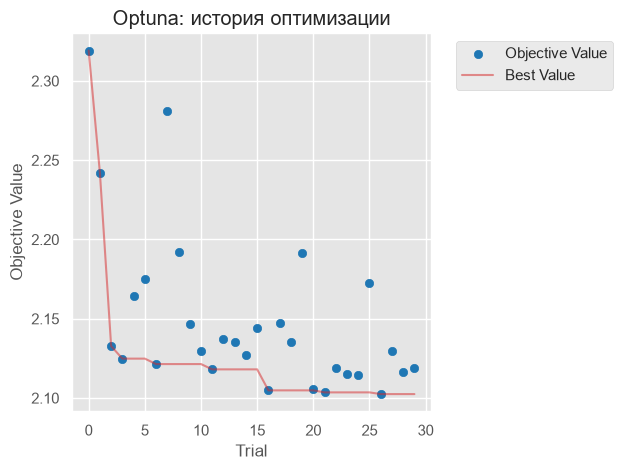

In [12]:
def optuna_objective(trial):
    hyperparameters = {
        "num_leaves": trial.suggest_int("num_leaves", 15, 255),
        "n_estimators": trial.suggest_int("n_estimators", 200, 1200),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 80),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 20, log=True),
    }
    fold_scores = cross_validate_in_time(
        build_lightgbm_pipeline(**hyperparameters), base_features["train"], targets["train"])
    return float(fold_scores.mean())

study = optuna.create_study(direction="minimize",
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(optuna_objective, n_trials=30)
best_hyperparameters = {**study.best_params, "subsample_freq": 1}

default_scores = cross_validate_in_time(build_lightgbm_pipeline(),
                                        base_features["train"], targets["train"])
improvement = default_scores.mean() - study.best_value
print(f"лучший триал #{study.best_trial.number}")
for name, value in study.best_params.items():
    print(f"  {name}: {value}")
print(f"\nCV MAE: до тюнинга {default_scores.mean():.3f} -> после {study.best_value:.3f} "
      f"(улучшение {improvement:.3f} мин, {improvement/default_scores.mean()*100:.1f}%)")

axis = optuna.visualization.matplotlib.plot_optimization_history(study)
axis.set_title("Optuna: история оптимизации")
plt.tight_layout(); plt.show()

## 9. Выбор на val: прямой таргет vs residual + буфер обещания (автор: Мокров Данила)

**Residual-приём.** Время приготовления — известный вход, а не неизвестность: учить модель имеет смысл только «дорожной» части. Прогноз = `приготовление + модель(факт − приготовление)`. Если зависимость действительно `время ≈ приготовление + дорога`, модели проще: постоянная часть не требует объяснения, и ошибиться в ней нельзя. Если нет — прямой таргет не хуже; какой вариант лучше для наших данных, покажет сравнение на val.

**Буфер обещания.** Опоздать с обещанием хуже, чем прийти раньше: пользователь лучше реагирует на «пришло раньше, чем обещали». Ищем минимальный буфер `b` (добавляем к прогнозу), при котором доля заказов «факт > обещание + 5 мин» на val ≤ 1.5%.

Сетка вариантов: {прямой таргет, residual} × {LightGBM (Optuna-тюнинг из §8), CatBoost (дефолт)} × {базовые, базовые+история}. Честности ради: CatBoost отдельно не тюним (Optuna × CatBoost × 4 фолда — десятки минут), но его дефолт уже лучший в CV §5 — если он проиграет тюненному LightGBM на val, тюнинг сделал бы его только сильнее, выбор от этого не меняется. Все сравнения — **только на val (24–27 окт), без 28–30 октября**.

In [13]:
class ResidualModel(BaseEstimator):
    """Прогноз = время приготовления + модель остатка (дорожной части)."""
    def __init__(self, pipeline):
        self.pipeline = pipeline
    def fit(self, features, target_values):
        self.pipeline.fit(features, target_values - features[PREPARATION_TIME].to_numpy())
        return self
    def predict(self, features):
        return features[PREPARATION_TIME].to_numpy() + self.pipeline.predict(features)


def fit_and_predict_variant(feature_frames, use_residual, model_factory):
    numeric_columns = [c for c in feature_frames["train"].columns if c not in CATEGORICAL_FEATURES]
    model = (ResidualModel(model_factory(numeric_columns)) if use_residual
             else model_factory(numeric_columns))
    model.fit(feature_frames["train"], targets["train"])
    return model.predict(feature_frames["val"])

def validation_metrics(prediction):
    absolute_error = np.abs(targets["val"] - prediction)
    rmse_far = np.sqrt(mean_squared_error(
        targets["val"][is_long_distance["val"]], np.asarray(prediction)[is_long_distance["val"]]))
    return {"MAE": absolute_error.mean(),
            "RMSE": np.sqrt(mean_squared_error(targets["val"], prediction)),
            "ошибка>5мин,%": (absolute_error > 5).mean() * 100,
            "RMSE>=10км": rmse_far}

def make_tuned_lightgbm(numeric_columns):
    return build_lightgbm_pipeline(numeric_columns=numeric_columns, **best_hyperparameters)

def make_default_catboost(numeric_columns):
    return Pipeline([("preprocessor", build_preprocessor(numeric_columns, native_categoricals=True)),
                     ("model", catboost_lib.CatBoostRegressor(
                         iterations=500, learning_rate=0.08, depth=6, random_seed=RANDOM_STATE,
                         verbose=0, allow_writing_files=False, cat_features=CATEGORICAL_FEATURES))])

TARGET_VARIANTS = {
    "A: LightGBM, прямой таргет, базовые": (base_features, False, make_tuned_lightgbm),
    "B: LightGBM, residual, базовые": (base_features, True, make_tuned_lightgbm),
    "C: LightGBM, прямой, базовые+история": (extended_features, False, make_tuned_lightgbm),
    "D: LightGBM, residual, базовые+история": (extended_features, True, make_tuned_lightgbm),
    "E: CatBoost, прямой, базовые": (base_features, False, make_default_catboost),
    "F: CatBoost, residual, базовые": (base_features, True, make_default_catboost),
}
validation_results = {}
validation_predictions = {}
for variant_name, (feature_frames, use_residual, model_factory) in TARGET_VARIANTS.items():
    prediction = fit_and_predict_variant(feature_frames, use_residual, model_factory)
    validation_predictions[variant_name] = prediction
    validation_results[variant_name] = validation_metrics(prediction)
    metrics = validation_results[variant_name]
    print(f"{variant_name:>38}: MAE={metrics['MAE']:.3f} RMSE={metrics['RMSE']:.3f} "
          f"ошибка>5мин={metrics['ошибка>5мин,%']:.1f}% RMSE>=10км={metrics['RMSE>=10км']:.3f}")

selected_variant = min(validation_results, key=lambda name: validation_results[name]["MAE"])
selected_uses_residual = "residual" in selected_variant
selected_feature_frames = (extended_features if "история" in selected_variant else base_features)
selected_model_factory = {name: spec[2] for name, spec in TARGET_VARIANTS.items()}[selected_variant]
print(f"\nвыбрано на val: {selected_variant}")

   A: LightGBM, прямой таргет, базовые: MAE=2.079 RMSE=2.609 ошибка>5мин=5.3% RMSE>=10км=3.164


        B: LightGBM, residual, базовые: MAE=2.052 RMSE=2.581 ошибка>5мин=5.1% RMSE>=10км=3.163


  C: LightGBM, прямой, базовые+история: MAE=2.086 RMSE=2.613 ошибка>5мин=5.4% RMSE>=10км=3.195


D: LightGBM, residual, базовые+история: MAE=2.071 RMSE=2.601 ошибка>5мин=5.2% RMSE>=10км=3.184


          E: CatBoost, прямой, базовые: MAE=2.048 RMSE=2.558 ошибка>5мин=5.1% RMSE>=10км=2.779


        F: CatBoost, residual, базовые: MAE=2.042 RMSE=2.551 ошибка>5мин=5.1% RMSE>=10км=2.812

выбрано на val: F: CatBoost, residual, базовые


### Подбор буфера обещания

Перебираем буфер от 0 до 3 минут с шагом 0.25. Слева — как падает доля поздних обещаний с ростом буфера; справа — цена: средний перезапас (на сколько минут в среднем обещаем больше факта). Выбираем минимальный буфер, при котором поздних обещаний не больше 1.5%.

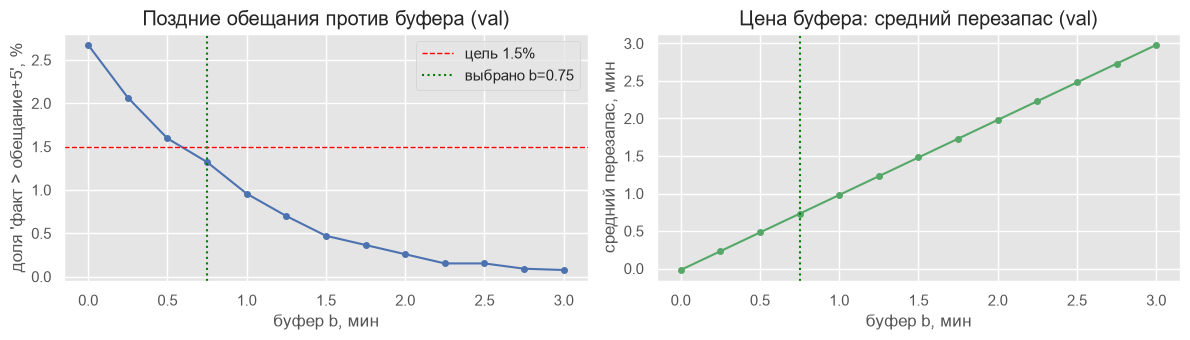

выбран буфер b = 0.75 мин (доля поздних 1.3%, перезапас +0.73 мин)


In [14]:
selected_validation_prediction = validation_predictions[selected_variant]
buffer_grid = np.round(np.arange(0, 3.01, 0.25), 2)
late_share = [(targets["val"].to_numpy() > selected_validation_prediction + b + 5).mean() * 100
              for b in buffer_grid]
mean_overshoot = [(selected_validation_prediction + b - targets["val"].to_numpy()).mean()
                  for b in buffer_grid]
promise_buffer_minutes = float(buffer_grid[np.argmax(np.array(late_share) <= 1.5)])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(buffer_grid, late_share, marker="o", ms=4, color="#4C72B0")
ax[0].axhline(1.5, color="red", ls="--", lw=1, label="цель 1.5%")
ax[0].axvline(promise_buffer_minutes, color="green", ls=":", lw=1.5,
              label=f"выбрано b={promise_buffer_minutes}")
ax[0].set_xlabel("буфер b, мин"); ax[0].set_ylabel("доля 'факт > обещание+5', %")
ax[0].set_title("Поздние обещания против буфера (val)"); ax[0].legend()
ax[1].plot(buffer_grid, mean_overshoot, marker="o", ms=4, color="#55A868")
ax[1].axvline(promise_buffer_minutes, color="green", ls=":", lw=1.5)
ax[1].set_xlabel("буфер b, мин"); ax[1].set_ylabel("средний перезапас, мин")
ax[1].set_title("Цена буфера: средний перезапас (val)")
plt.tight_layout(); plt.show()
chosen_index = int(promise_buffer_minutes / 0.25)
print(f"выбран буфер b = {promise_buffer_minutes} мин "
      f"(доля поздних {late_share[chosen_index]:.1f}%, "
      f"перезапас +{mean_overshoot[chosen_index]:.2f} мин)")

## 10. Финальная оценка: test 28–30 октября (автор: Мокров Данила)

- ошибка > 5 мин — доля заказов, где модель ошиблась больше чем на 5 минут (в любую сторону — и в большую, и в меньшую). Это обычная метрика точности модели.
- факт > обещание + 5 мин — доля заказов, где доставка заняла больше времени, чем мы пообещали клиенту. Это метрика «опозданий глазами клиента»: опоздать хуже, чем привезти раньше.

В конце раздела — дополнительная проверка. В разделе 1 мы выяснили, что данные почти не меняются ото дня ко дню, поэтому случайное разбиение 80/20 не должно приукрашивать качество. Здесь проверяем это на числах: обучаем ту же модель на случайном разбиении и сравниваем с нашим временным тестом.

In [15]:
def collect_test_metrics(true_values, prediction, model_name):
    absolute_error = np.abs(true_values - prediction)
    rmse = np.sqrt(mean_squared_error(true_values, prediction))
    rmse_far = np.sqrt(mean_squared_error(
        np.asarray(true_values)[is_long_distance["test"]],
        np.asarray(prediction)[is_long_distance["test"]]))
    return {"модель": model_name, "MAE": absolute_error.mean(), "RMSE": rmse,
            "ошибка>5мин,%": (absolute_error > 5).mean() * 100,
            "факт>обещ+5,%": (np.asarray(true_values) > np.asarray(prediction) + 5).mean() * 100,
            "RMSE>=10км": rmse_far, "R2": r2_score(true_values, prediction)}

# финальная модель: выбранный на val вариант, обучена на train-периоде
final_numeric_columns = [c for c in selected_feature_frames["train"].columns
                         if c not in CATEGORICAL_FEATURES]
final_model = (ResidualModel(selected_model_factory(final_numeric_columns))
               if selected_uses_residual else selected_model_factory(final_numeric_columns))
final_model.fit(selected_feature_frames["train"], targets["train"])
test_predictions = final_model.predict(selected_feature_frames["test"])
test_predictions_with_buffer = test_predictions + promise_buffer_minutes

test_metric_rows = [
    collect_test_metrics(targets["test"], np.full(len(targets["test"]), targets["train"].median()),
                         "Dummy (медиана train)"),
    collect_test_metrics(targets["test"], baseline_estimate["test"].to_numpy(), "Оценка датасета"),
    collect_test_metrics(targets["test"], baseline_estimate["test"].to_numpy() + promise_buffer_minutes,
                         f"Оценка датасета + буфер {promise_buffer_minutes}"),
]
for model_name, model in CANDIDATE_MODELS.items():
    model.fit(base_features["train"], targets["train"])
    test_metric_rows.append(collect_test_metrics(targets["test"],
                                                 model.predict(base_features["test"]), model_name))
lightgbm_direct = build_lightgbm_pipeline(**best_hyperparameters)
lightgbm_direct.fit(base_features["train"], targets["train"])
test_metric_rows.append(collect_test_metrics(
    targets["test"], lightgbm_direct.predict(base_features["test"]),
    "LightGBM Optuna, прямой таргет"))
test_metric_rows.append(collect_test_metrics(targets["test"], test_predictions,
                                             f"ФИНАЛ: {selected_variant}"))
test_metric_rows.append(collect_test_metrics(
    targets["test"], test_predictions_with_buffer,
    f"ФИНАЛ + буфер {promise_buffer_minutes} мин (боевой)"))

test_metrics_table = (pd.DataFrame(test_metric_rows)
                      .set_index("модель").sort_values("RMSE"))
display(test_metrics_table.round(3))

,MAE,RMSE,"ошибка>5мин,%","факт>обещ+5,%",RMSE>=10км,R2
модель,,,,,,
"ФИНАЛ: F: CatBoost, residual, базовые",2.017,2.528,4.719,2.299,2.664,0.972
CatBoost,2.027,2.541,4.638,2.238,2.830,0.971
"LightGBM Optuna, прямой таргет",2.045,2.568,5.001,2.400,2.833,0.971
LightGBM,2.066,2.584,5.243,2.722,2.848,0.970
XGBoost,2.062,2.600,5.566,2.642,2.931,0.970
ФИНАЛ + буфер 0.75 мин (боевой),2.115,2.650,5.808,1.109,2.839,0.969
RandomForest,2.153,2.701,6.271,3.327,3.251,0.968
Lasso,2.149,2.706,6.453,2.319,3.400,0.967
Ridge,2.170,2.729,6.755,2.722,3.502,0.967


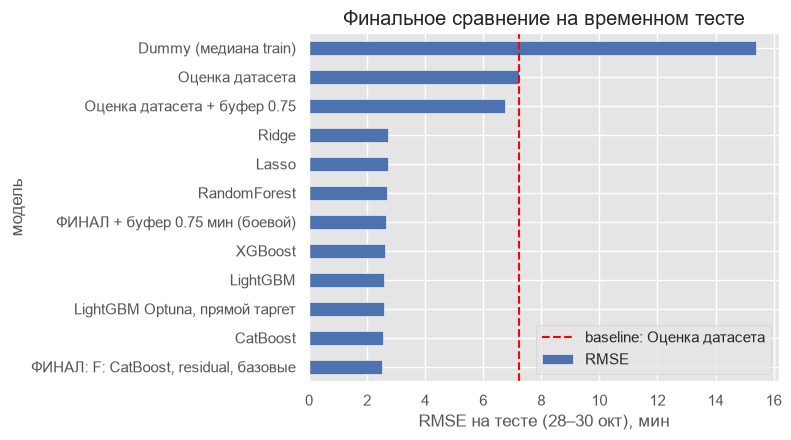

In [16]:
axis = test_metrics_table["RMSE"].plot(kind="barh", figsize=(8, 4.5), color="#4C72B0")
axis.axvline(test_metrics_table.loc["Оценка датасета", "RMSE"], color="red", ls="--",
             label="baseline: Оценка датасета")
axis.set_xlabel("RMSE на тесте (28–30 окт), мин")
axis.set_title("Финальное сравнение на временном тесте")
axis.legend()
plt.tight_layout(); plt.show()

### Дополнительная проверка: случайный сплит против временного

Обучаем ту же модель (CatBoost с прямым таргетом) при случайном разбиении 80/20 и сравниваем с её же результатом на нашем временном тесте из таблицы выше.

In [17]:
random_train_features, random_test_features, random_train_target, random_test_target =     train_test_split(base_feature_matrix, target, test_size=0.2, random_state=RANDOM_STATE)
random_split_model = make_default_catboost(NUMERIC_FEATURES)
random_split_model.fit(random_train_features, random_train_target)
random_split_prediction = random_split_model.predict(random_test_features)
catboost_time_row = test_metrics_table.loc["CatBoost"]
print(f"случайный 80/20, CatBoost (прямой таргет): "
      f"MAE = {mean_absolute_error(random_test_target, random_split_prediction):.3f} | "
      f"RMSE = {np.sqrt(mean_squared_error(random_test_target, random_split_prediction)):.3f}")
print(f"временной тест, CatBoost (прямой таргет):  "
      f"MAE = {catboost_time_row['MAE']:.3f} | RMSE = {catboost_time_row['RMSE']:.3f}")

случайный 80/20, CatBoost (прямой таргет): MAE = 2.048 | RMSE = 2.570
временной тест, CatBoost (прямой таргет):  MAE = 2.027 | RMSE = 2.541


## 11. Ошибки по сегментам (автор: Мокров Данила)

Средняя метрика может скрывать проблемы: модель бывает точна в среднем, но заметно ошибается на отдельных группах заказов — например, в шторм, в высокие пробки или на дальних маршрутах, где ошибка обходится дороже всего. Поэтому разбиваем ошибки финальной модели по сегментам. Сегменты выбираем только по информации, которая известна уже при оформлении заказа: город, уровень пробок, погода, тип ресторана и дистанция.

--- ошибка по city ---


,заказов,"MAE, мин",медиана |ош.|
city,,,
City_A,1970,2.01,1.71
City_B,1496,2.05,1.78
City_C,974,2.00,1.65
City_D,519,1.98,1.69


--- ошибка по traffic_level ---


,заказов,"MAE, мин",медиана |ош.|
traffic_level,,,
Low,1512,2.00,1.74
Medium,1910,1.99,1.69
High,1537,2.07,1.71


--- ошибка по weather ---


,заказов,"MAE, мин",медиана |ош.|
weather,,,
Clear,1623,1.97,1.65
Cloudy,2028,2.03,1.74
Rain,1308,2.05,1.76


--- ошибка по restaurant_type ---


,заказов,"MAE, мин",медиана |ош.|
restaurant_type,,,
Cafe,795,2.00,1.71
Casual Dining,1332,2.01,1.71
Fast Food,2734,2.03,1.73
Fine Dining,98,1.93,1.73


--- ошибка по дистанции ---


,заказов,"MAE, мин",медиана |ош.|
distance_km,,,
"(0.0, 2.0]",530,1.99,1.66
"(2.0, 4.0]",1893,2.06,1.77
"(4.0, 6.0]",1350,1.99,1.65
"(6.0, 10.0]",929,1.99,1.75
"(10.0, 20.1]",257,2.05,1.69


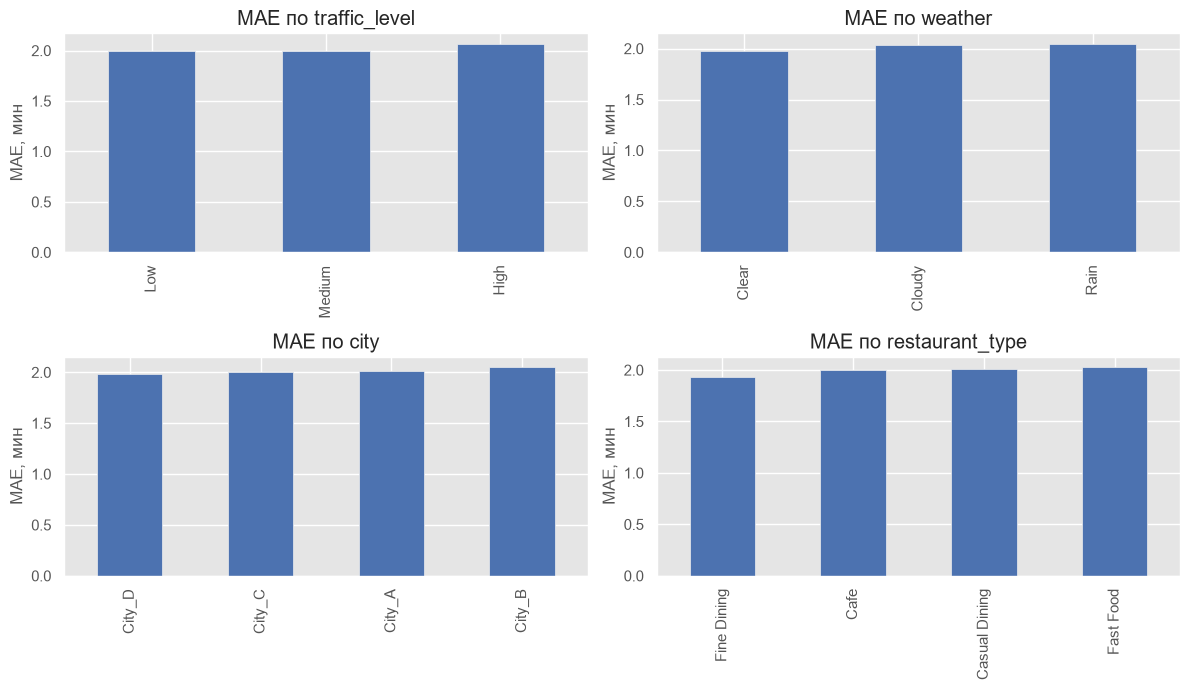

In [18]:
test_segments = orders.loc[test_mask, ["city", "traffic_level", "weather",
                                       "restaurant_type", "distance_km"]].copy()
test_segments["absolute_error"] = np.abs(targets["test"].to_numpy() - test_predictions)

category_orders = {"traffic_level": ["Low", "Medium", "High"],
                   "weather": ["Clear", "Cloudy", "Rain", "Storm"]}
for column in ["city", "traffic_level", "weather", "restaurant_type"]:
    segment_table = (test_segments.groupby(column)["absolute_error"]
                     .agg(["count", "mean", "median"]).round(2))
    if column in category_orders:  # в тест-окне могут быть не все категории
        segment_table = segment_table.loc[[c for c in category_orders[column]
                                           if c in segment_table.index]]
    segment_table.columns = ["заказов", "MAE, мин", "медиана |ош.|"]
    print(f"--- ошибка по {column} ---")
    display(segment_table)

distance_table = (test_segments
                  .groupby(pd.cut(test_segments["distance_km"], [0, 2, 4, 6, 10, 20.1]),
                           observed=True)["absolute_error"]
                  .agg(["count", "mean", "median"]).round(2))
distance_table.columns = ["заказов", "MAE, мин", "медиана |ош.|"]
print("--- ошибка по дистанции ---")
display(distance_table)

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for subplot, column in zip(ax.flat, ["traffic_level", "weather", "city", "restaurant_type"]):
    segment_means = test_segments.groupby(column)["absolute_error"].mean().sort_values()
    if column in category_orders:
        segment_means = segment_means.reindex(
            [c for c in category_orders[column] if c in segment_means.index])
    segment_means.plot(kind="bar", ax=subplot, color="#4C72B0", title=f"MAE по {column}")
    subplot.set_xlabel(""); subplot.set_ylabel("MAE, мин")
plt.tight_layout(); plt.show()

## 12. Интерпретация: permutation importance и SHAP (автор: Мокров Данила)

Разбираем финальную модель двумя независимыми способами.

**Permutation importance (важность перемешиванием).** Берём один признак, случайно перемешиваем его значения между заказами и смотрим, на сколько минут ухудшится MAE. Если метрика заметно портится — модель действительно опирается на этот признак.

**SHAP.** Объясняет каждый отдельный прогноз: для конкретного заказа показывает, какие признаки и на сколько минут сдвинули прогноз вверх или вниз. Вклады признаков устроены так, что в сумме дают прогноз модели точно (математическая основа — значения Шепли из теории игр). График-«рой» (beeswarm) ниже собирает такие объяснения сразу по трём тысячам заказов: по каждой строке видно и силу влияния признака, и направление — например, у дистанции высокие значения (красные точки) сдвигают прогноз вправо, то есть увеличивают время доставки.

Примечание к ячейкам ниже: TreeExplainer работает и с LightGBM, и с CatBoost. Если выбран residual-вариант, SHAP объясняет «дорожную» часть прогноза: известное время приготовления входит в итоговый прогноз константой, а не объясняется отдельно.


Топ-10 (прирост MAE при перемешивании, мин):
distance_km                            6.192
restaurant_preparation_time_minutes    6.008
distance_x_traffic                     3.593
distance_x_weather                     1.271
weather_ord                            0.246
traffic_ord                            0.053
restaurant_primary_category            0.001
customer_type                          0.001
price_per_item                         0.001
distance_at_cap                        0.001


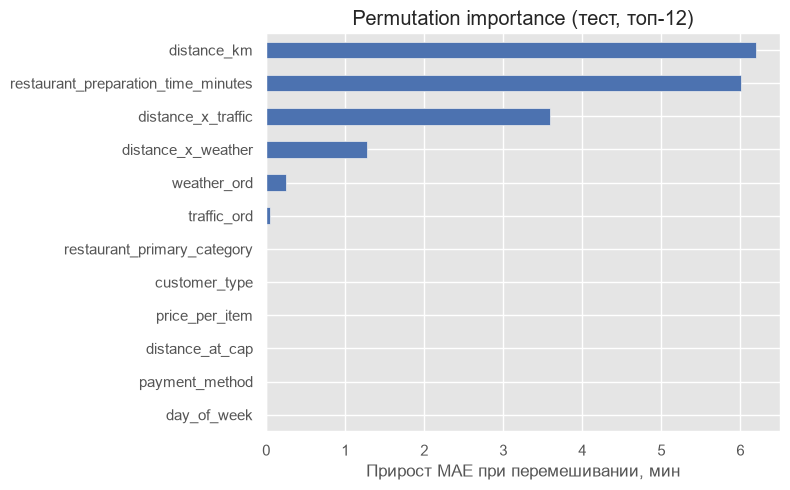

In [19]:
permutation_result = permutation_importance(
    final_model, selected_feature_frames["test"], targets["test"], n_repeats=5,
    random_state=RANDOM_STATE, scoring="neg_mean_absolute_error")
permutation_importances = (pd.Series(permutation_result.importances_mean,
                                     index=selected_feature_frames["test"].columns)
                           .sort_values(ascending=True))
print("Топ-10 (прирост MAE при перемешивании, мин):")
print(permutation_importances.tail(10).round(3)[::-1].to_string())

plt.figure(figsize=(8, 5))
permutation_importances.tail(12).plot(kind="barh", color="#4C72B0")
plt.xlabel("Прирост MAE при перемешивании, мин")
plt.title("Permutation importance (тест, топ-12)")
plt.tight_layout(); plt.show()

SHAP-матрица: 3000 заказов × 21 признаков


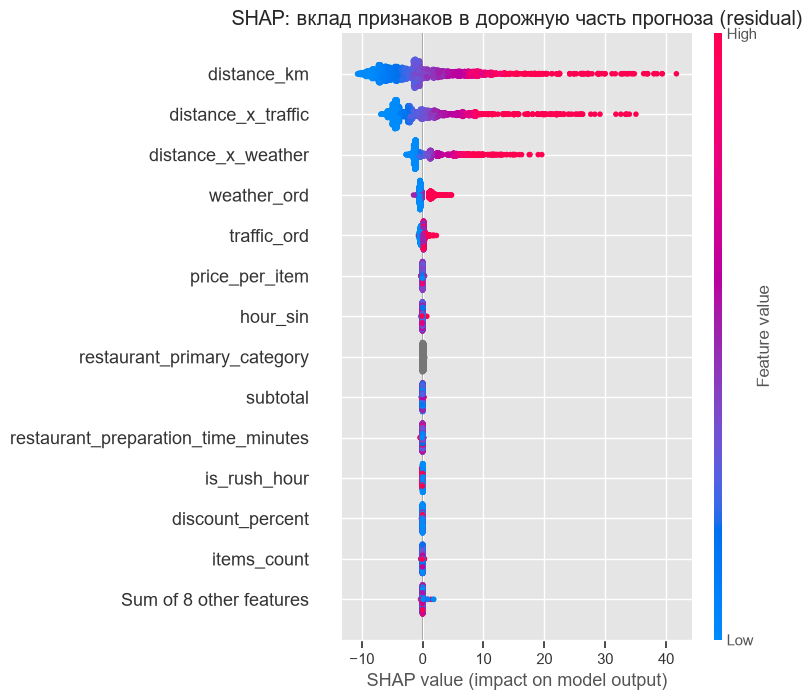

In [20]:
inner_pipeline = final_model.pipeline if selected_uses_residual else final_model
inner_model = inner_pipeline.named_steps["model"]
transformed_test = inner_pipeline.named_steps["preprocessor"].transform(
    selected_feature_frames["test"])

shap_explainer = shap.TreeExplainer(inner_model)
shap_values = shap_explainer(transformed_test.iloc[:3000])
explained_part = ("дорожную часть прогноза (residual)" if selected_uses_residual
                  else "прогноз времени доставки (минуты)")
print(f"SHAP-матрица: {shap_values.shape[0]} заказов × {shap_values.shape[1]} признаков")

plt.figure()
shap.plots.beeswarm(shap_values, max_display=14, show=False)
plt.title(f"SHAP: вклад признаков в {explained_part}")
plt.tight_layout(); plt.show()

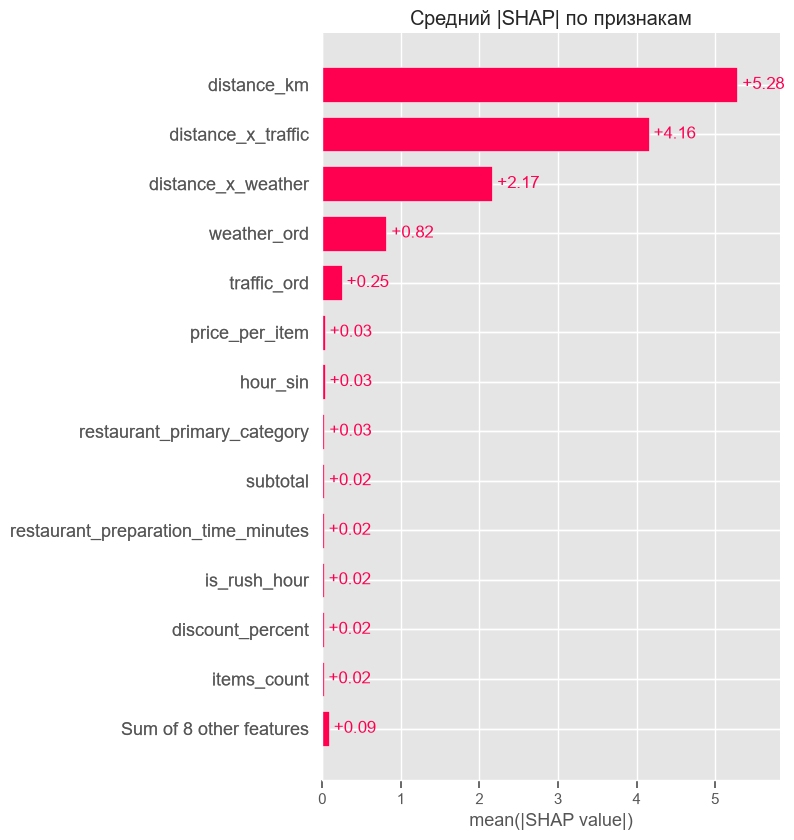

In [21]:
plt.figure()
shap.plots.bar(shap_values, max_display=14, show=False)
plt.title("Средний |SHAP| по признакам")
plt.tight_layout(); plt.show()

## 13. Выводы

**Протокол.** Всё честно по времени: train 1–23 окт → все решения на val 24–27 окт → одна финальная оценка на test 28–30 окт. CV и обучение — только по заказам, завершившимся к началу окна (point-in-time). Модель, признаки, вариант таргета и буфер выбраны без единого взгляда на test.

**Итог на тесте (28–30 октября, 4 959 заказов):**

| Модель | MAE | RMSE | \|ош\|>5мин | Факт>обещ+5 | RMSE≥10км | R² |
|---|---|---|---|---|---|---|
| Dummy (медиана) | 11.10 | 15.41 | 69.1% | 37.8% | 41.43 | −0.06 |
| Оценка датасета (baseline) | 5.69 | 7.23 | 44.2% | 42.6% | 11.64 | 0.77 |
| LightGBM Optuna (прямой) | 2.045 | 2.568 | 5.0% | 2.4% | 2.83 | 0.971 |
| **ФИНАЛ: CatBoost + residual** | **2.017** | **2.528** | 4.7% | 2.3% | **2.66** | **0.972** |
| **ФИНАЛ + буфер 0.75 мин (боевой)** | 2.115 | 2.650 | 5.8% | **1.1%** | 2.84 | 0.969 |

**Ключевые выводы:**

1. **Победитель — CatBoost с residual-таргетом.** Нативное кодирование категорий (ordered target statistics — идейно тот же TE из §4.3, но встроенный) лучше всего ложится на временные фолды: на дефолтных параметрах обгоняет и LightGBM с Optuna-тюнингом (CV 2.074 против 2.102), и на val (2.042 против 2.052), и на test. CatBoost отдельно не тюнили (дорогой перебор) — ограничение зафиксировано честно.
2. **Residual-приём работает.** `прогноз = приготовление + модель(факт − приготовление)` улучшает обе модели: LightGBM 2.079 → 2.052, CatBoost 2.048 → 2.042 на val; test подтверждает (2.017 против 2.027). Логика верная: время приготовления — известный вход, модель учит только дорожную часть (~19.5 мин в среднем) и не может ошибиться в постоянной части.
3. **История сущностей на этих данных не помогает — и это честный результат абляции.** Point-in-time target encoding по restaurant_id/driver_id/delivery_area и загруженность за час построены корректно, но без них одинаково или лучше (CV: 2.133 → 2.131/2.150/2.156; val: варианты C/D хуже A/B). По построению данных индивидуальных эффектов нет — «характер» ресторана уже описан типом и prep-таймом, курьер без сигнала (EDA). В реальных данных, где есть «медленные кухни», такие признаки — главный источник качества; метод отработан и задокументирован.
4. **Буфер покупает то, что нужно бизнесу.** +0.75 мин к обещанию сокращает долю поздних обещаний вдвое: 2.3% → 1.1% на test (правило «≤1.5% на val» дало b=0.75). Цена — MAE 2.017 → 2.115. Для сравнения: собственная оценка датасета опаздывает с обещанием в 42.6% заказов.
5. **Случайный или временной сплит? Проверили на числах.** Обучили одну и ту же модель (CatBoost, прямой таргет) двумя способами: при случайном разбиении заказов 80/20 и по нашему правилу «обучение на прошлом, проверка на будущем». Результаты почти одинаковые: MAE 2.048 против 2.027, RMSE 2.570 против 2.541. Дело в том, что данные за месяц почти не меняются (раздел 1): «будущее» похоже на «прошлое», и подглядывание в будущее ничего не даёт. Но рассчитывать на это нельзя: в реальном сервисе данные меняются (сезонность, рост числа заказов, новые районы), и тогда случайный сплит начал бы завышать качество — модель незаметно обучалась бы на похожих «завтрашних» заказах. Временной протокол устроен как боевая задача — учимся только на прошлом, предсказываем только будущее, — поэтому выбираем его независимо от того, что на этих данных цифры совпали.
6. **Масштабирование признаков: на качество не влияет, на коэффициенты — влияет.** Мы попробовали обучать модели без масштабирования и с тремя разными способами (StandardScaler, MinMaxScaler, RobustScaler) — точность (MAE) не изменилась ни у бустинга, ни у линейной модели. Для деревьев это ожидаемо: им всё равно, в каких единицах измерен признак. Для Ridge так вышло потому, что при слабой регуляризации его решение почти совпадает с обычной линейной регрессией, а её предсказания от масштаба не зависят. Масштабирование всё равно осталось в линейных моделях по другой причине: признаки измеряются в разных единицах (километры, минуты, рубли), и без выравнивания шкал штраф регуляризации давит на признаки неравномерно, а коэффициенты нельзя сравнивать между собой. Итог: линейным моделям — StandardScaler, деревьям — без масштабирования.
7. **Что на самом деле определяет время доставки.** Два независимых способа объяснения модели — permutation importance и SHAP — дали одинаковый ответ. Сильнее всего на прогноз влияют четыре признака: дистанция, время приготовления и два сконструированных нами взаимодействия — «дистанция × пробки» и «дистанция × погода». Это важный результат: признаки, придуманные по итогам EDA, действительно работают, и это подтверждено дважды. Уровень пробок и погоды сами по себе дают лишь небольшую подстройку, а способ оплаты, город и тип клиента модель игнорирует как шум.
8. **Модель ошибается одинаково везде.** Средняя ошибка держится в узком коридоре 1.93–2.07 минуты — во всех городах, при любом уровне пробок, в любую погоду (в тестовые дни штормов, правда, не случилось), во всех типах ресторанов и на всех дистанциях. Групп заказов, на которых модель «сыпется», нет. Чуть труднее всего дальние заказы: от 10 км ошибка выше (RMSE 2.66 против 2.53 в среднем), но и там модель точнее оценки датасета в 4.4 раза.

**Практическая ценность.** Итоговая модель с буфером ошибается в медиане примерно на 1.7 минуты и опаздывает относительно обещанного времени лишь в ~1% заказов. Этого достаточно для двух боевых задач: честно обещать клиенту время доставки и заранее помечать заказы, которым грозит опоздание, — чтобы успеть отреагировать (сменить курьера, предупредить клиента).

**Ограничения.** Первое: победивший CatBoost мы не тюнили через Optuna (это десятки минут вычислений на каждый прогон) — возможно, он стал бы ещё точнее. Второе: тест — это только 3 дня, 28–30 октября; данные внутри месяца не менялись, но за пределами месяца сезонность и тренды мы проверить не можем. Третье: финальная модель обучена только на заказах до 23 октября — при реальном внедрении её нужно периодически переобучать на всех накопившихся заказах и следить, не начинает ли качество падать (признак дрейфа данных).